# Bulk SNR of β Pic b, HR 8799 c and DH Tau b for five instrument setups

For five instrument setups and three planets, this notebook computes the **expected bulk SNR** after a 5 h
observation (modulation period 10 h, i.e. half an array rotation) for a **known (fixed)** and a **marginalised**
planet position. It runs the processing of `prototype_pipeline.ipynb` for `N_REALISATIONS` independent noise
realisations per (planet, setup), corrects it for the biases listed below, and compares the result with the expected
SNR from the Fisher matrix. Section 7 shows the SNR of all planets and setups in a heatmap, for a selectable case (known or marginalised position) and estimate (pass 1 / pass 2, with or without the noise-bias correction, or the Fisher expectation).

**Bulk SNR.** As in the prototype, $\mathrm{SNR}^2 = \hat s^\mathsf{T} C^{-1} \hat s$ with $\hat s$ the fitted SED and
$C$ the flux covariance of the ML fit (`MLSEDEstimationModule`): the $n_\lambda \times n_\lambda$ covariance of the
`fix_position=True` fit (known position), or the flux block of the $(n_\lambda+2)^2$ covariance of the free-position
fit (marginalised).

## Biases of the prototype SNR, and their corrections

1. **The noise model leaves out the planet's photon noise** (the largest effect for bright planets).
   `ZCAWhiteningModule` estimates the noise from a *planet-free* simulation. When the planet is bright compared with
   the background (cold optics, deep null, small aperture), its own shot noise dominates, so the channel weights are
   not optimal, and lmfit's covariance, rescaled by one global reduced $\chi^2$, is wrong channel by channel. The
   reported SNR is then off in either direction (for β Pic b ≈ 40 % low for the cryogenic setup, ≈ 4 % high for the
   large warm one). **Correction:** a second pass. The data are re-whitened with the per-sample Poisson variance
   $\sigma^2_{\lambda t} = b_\lambda + m_{\lambda t}$, where $m$ is the planet model counts of the first-pass fit and
   $b_\lambda$ = the time mean of the data minus that of $m$ (the background level), and fitted again. Without
   instrument instability noise, all noise terms are Poisson (photon noise and dark current); the variance-to-mean
   ratio of a planet-free simulation, printed in section 5, checks this.
2. **Noise bias of $\hat s^\mathsf{T} C^{-1} \hat s$.** With $\hat s = s + n$, $n \sim \mathcal N(0, C)$:
   $E[\hat s^\mathsf{T} C^{-1} \hat s] = s^\mathsf{T} C^{-1} s + n_\lambda$, so even planet-free data give
   $\mathrm{SNR} \approx \sqrt{n_\lambda} \approx 4.7$. This holds for both cases (in the marginalised case, $C$ is the
   marginal flux covariance, i.e. the covariance of $\hat s$). **Correction:**
   $\langle \mathrm{SNR}\rangle = \sqrt{\langle \hat s^\mathsf{T} C^{-1} \hat s\rangle - n_\lambda}$. Relative size
   $n_\lambda / 2\mathrm{SNR}^2$: negligible at SNR ≈ 200, ≈ 3 % at SNR ≈ 20, large below SNR ≈ 10.
3. **Averaging.** $\langle\sqrt{x}\rangle \neq \sqrt{\langle x\rangle}$, so the realisations are averaged in
   $\mathrm{SNR}^2$ and the square root is taken at the end.
4. **Correlated calibration noise.** `ZCAWhiteningModule` simulates its calibration with
   `PHRINGE(seed=pipeline.seed)`. With a fixed pipeline seed, this re-seeds torch with the seed of the data, so the
   calibration repeats the noise draws of the data. Here the pipeline runs with `seed=None`, and each realisation
   seeds torch once itself: data and calibration are independent, and the run is reproducible.
5. **Wrong peak of the position search.** At low SNR, the grid search of the free fit can lock on a wrong peak
   (and pass 2, started at the pass-1 position, stays there). Free fits more than `MAX_POS_OFFSET_SIGMA` from the true
   position or its mirror image (the single Bracewell has an exact $\pm(x, y)$ ambiguity that leaves the SED
   unchanged) are counted and left out of the marginalised average of their pass.

(Also: with `diagonal_only=True`, the ZCA weights are the diagonal of $\hat C^{-1/2}$ of a noisy 22 × 22 sample
covariance from 60 time steps, not $1/\hat\sigma_\lambda$. The second pass does not use them.)

## Reference: expected SNR from the Fisher matrix

$F_{ij} = \sum_{\lambda,t} \partial_i m_{\lambda t}\,\partial_j m_{\lambda t} / \sigma^2_{\lambda t}$ at the true
parameters (fluxes, $x$, $y$), with $m$ the noiseless, mean-subtracted planet counts and
$\sigma^2_{\lambda t} = b_\lambda + m^\mathrm{raw}_{\lambda t}$ (background from a planet-free simulation plus the
planet's own counts): $\mathrm{SNR}_\mathrm{known}^2 = s^\mathsf{T} F_{ff}\, s$ and
$\mathrm{SNR}_\mathrm{marg}^2 = s^\mathsf{T}[(F^{-1})_{ff}]^{-1} s$. The bias-corrected Monte-Carlo average of the
second pass should agree with it.

In [39]:
import contextlib
import importlib.util
import io
import json
import time
import warnings
from pathlib import Path
from types import SimpleNamespace

import astropy.units as u
import numpy as np
import pandas as pd
import torch
from matplotlib import pyplot as plt
from matplotlib.colors import ListedColormap, LogNorm

from phringe.core.instrument import Instrument
from phringe.core.observation import Observation
from phringe.core.scene import Scene
from phringe.core.sources.local_zodi import LocalZodi
from phringe.lib.array_configuration import SBWConfiguration
from phringe.lib.beam_combiner import SingleBracewell
from phringe.main import PHRINGE
import phringe.io.sed_loader as sed_loader_module
from phringe.io.sed_loader import SEDLoader

from lifesimmc.core.pipeline import Pipeline
from lifesimmc.core.modules.base_module import BaseModule
from lifesimmc.core.modules.loading.setup_module import SetupModule
from lifesimmc.core.modules.generating.data_generation_module import DataGenerationModule
from lifesimmc.core.modules.generating.template_generation_module import TemplateGenerationModule
from lifesimmc.core.modules.processing.zca_whitening_module import ZCAWhiteningModule
from lifesimmc.core.modules.processing.ml_parameter_estimation_module import MLSEDEstimationModule
from lifesimmc.core.resources.data_resource import DataResource
from lifesimmc.core.resources.planet_resource import PlanetResource
from lifesimmc.core.resources.resource_collection import ResourceCollection
from lifesimmc.core.resources.transformation_resource import TransformationResource

RAD_TO_MAS = 180 / np.pi * 3600e3


def quiet(func, *args, **kwargs):
    # The lifesimmc modules print progress messages; keep the notebook output readable
    with warnings.catch_warnings(), contextlib.redirect_stdout(io.StringIO()):
        warnings.simplefilter('ignore')
        return func(*args, **kwargs)

## 1. Settings

In [40]:
# --- Observation ---
T_OBS = 5 * 3600            # total integration time [s]
T_MOD = 10 * 3600           # modulation period [s] (one full array rotation); T_OBS / T_MOD = half a rotation
DIT = 5 * 60                # detector integration time [s] -> T_OBS / DIT = 60 time steps, as in the prototype

# --- Monte Carlo ---
N_REALISATIONS = 10          # noise realisations per (planet, setup) (~45 s each on CPU, much less on GPU)
BASE_SEED = 1000            # realisation i of every (planet, setup) uses seed BASE_SEED + i
MAX_POS_OFFSET_SIGMA = 5    # free fits further than this from +/- the true position count as failed

# --- Simulation ---
GRID_SIZE = 60              # spatial grid of the extended sources and the position-search templates
GPU_INDEX = None            # e.g. 2 on the GPU machine; None -> CPU

# --- Output ---
# Per planet, next to its spectrum (as in the prototype): <spectrum folder>/setup_snr/realisations_<planet>.jsonl
# (one line per (setup, realisation); finished runs are reused) and the SNR-per-setup plot.
# All planets together (summary table, heatmap):
COMBINED_DIR = Path('plots/setup_snr')
COMBINED_DIR.mkdir(parents=True, exist_ok=True)

## 2. Targets

Each target is a config file (star, exozodi, optional debris disks, planets) and the name of the planet in it. Only
that planet is put in the scene. `sed_file` replaces the config's spectrum, e.g. when the config points at a
placeholder: for DH Tau b, `setup/spectra/dh_tau_b.txt` is an ATMO 2020 model scaled to the WISE W1 magnitude, in
W/m²/µm, scaled with the planet radius and the distance.

In [41]:
# planet name -> config file (relative to lifesim_plots), planet variable in it, optional replacement spectrum
TARGETS = {
    'bet Pic b': dict(config='setup/spectra/BetaPic/bet_pic.py', planet='bet_pic_b'),
    'HR 8799 c': dict(config='setup/spectra/HR8799/hr_8799.py', planet='hr_8799_c'),
    'DH Tau b':  dict(config='setup/config/dh_tau.py', planet='dh_tau_b',
                      sed_file='setup/spectra/dh_tau_b.txt', sed_units='W/m2/um'),
}


def load_target(name):
    # Executes the config and returns its star, exozodi, disks and the planet (with `sed_file` if given)
    target = TARGETS[name]
    path = Path(target['config'])
    spec = importlib.util.spec_from_file_location(f'_target_{path.stem}', path)
    module = importlib.util.module_from_spec(spec)
    # A config may point at a missing spectrum (PLACEHOLDER.txt): load it without, then use `sed_file`
    original = sed_loader_module.SEDLoader
    sed_loader_module.SEDLoader = lambda **kw: original(**kw) if Path(kw['path_to_file']).exists() else None
    try:
        quiet(spec.loader.exec_module, module)
    finally:
        sed_loader_module.SEDLoader = original

    planet = getattr(module, target['planet'])
    if 'sed_file' in target:
        planet = planet.model_copy(update={'sed_loader': SEDLoader(
            path_to_file=target['sed_file'], sed_units=target['sed_units'], wavelength_units='um',
            observed_planet_radius=planet.radius, observed_host_star_distance=module.star.distance)})
    if planet.sed_loader is None:
        raise FileNotFoundError(f'{name}: the config has no spectrum file; set sed_file in TARGETS')
    out_dir = Path(planet.sed_loader.path_to_file).parent / 'setup_snr'
    out_dir.mkdir(exist_ok=True)
    slug = name.lower().replace(' ', '_')
    return dict(star=module.star, exozodi=getattr(module, 'exozodi', None), disks=list(getattr(module, 'disks', [])),
                planet=planet, results_file=out_dir / f'realisations_{slug}.jsonl',
                plot_file=out_dir / f'snr_per_setup_{slug}.png')


LOADED = {name: load_target(name) for name in TARGETS}
pd.DataFrame([dict(planet=name, star=t['star'].name, distance_pc=round(t['star'].distance / 3.0857e16, 1),
                   n_disks=len(t['disks']), spectrum=Path(t['planet'].sed_loader.path_to_file).name)
              for name, t in LOADED.items()]).set_index('planet')

,star,distance_pc,n_disks,spectrum
planet,,,,
bet Pic b,bet Pic,19.4,3,betapicb_exorem_interpolated_spectrum.dat
HR 8799 c,HR 8799,41.2,0,hr_8799_c.txt
DH Tau b,DH Tau,134.8,0,dh_tau_b.txt


## 3. Instrument setups

Each setup is a complete design with a different aperture $D$, nulling baseline $B$ and thermal and detector
properties, chosen so that the setups reach **similar** SNRs for β Pic b. In this model:

* the planet signal and the stellar leakage (null depth × star) scale as $D^2$;
* the thermal background of the mirror and of the pre-fibre optics does **not** depend on $D$ (single-mode étendue
  $A\Omega = \lambda^2$), and rises steeply with temperature at 4–5 µm (≈ 27 e⁻/s per spectral bin at 160/120 K,
  ≈ 0 below 80 K);
* the dark current (e⁻/s/pixel, 2.2 pixels per bin) does not depend on $D$ either;
* the detector's own thermal emission is negligible below ~100 K at these wavelengths.

A smaller aperture therefore needs colder optics, a deeper null and a lower dark current to keep the SNR. PHRINGE
does not derive the dark current from the detector temperature, so each setup assumes a value consistent with its
detector temperature. Once the background is suppressed this far, the planet's own photon noise becomes the main
noise term, so the small cold setups gain less than the background alone suggests.

**Baseline.** The baseline sets where a planet at separation $\theta$ sits on the transmission pattern
$\sin^2(\pi B\theta/\lambda)$; the optimal baseline is $B_\mathrm{opt} = 0.606\,\lambda/\theta$ (≈ 1.3 m at 4.5 µm
for β Pic b at 424 mas). The **short baseline** setup keeps the known-position SNR but puts the planet on the rising
flank of the first transmission peak. There, a radial shift of the planet changes all channels together, much like a
flux scaling, so flux and position become degenerate and the marginalised SNR drops by an order of magnitude.

**Field of view.** The single-mode fibre limits the field of view to $\approx \lambda/D$; PHRINGE cuts it off at a
half width of ≈ 1.7–2.6″ for $D$ = 0.2–0.3 m (larger at longer wavelengths). DH Tau b at 2.45″ is outside it for the
large apertures; these cells are marked in the results.

Fixed for all setups (from `setup/prototype_setup.py`): 4–5 µm at R = 100, total throughput 0.12, mirror emissivity
0.06 and throughput 0.94, pre-fibre emissivity 1.0, QE 0.7, NIRSpec-like detector (18 µm pixels, 2.2 pixels per bin).

In [42]:
# name -> D [m], B [m], T_mirror / T_instr / T_det [K], null depth, dark current [e-/s/pixel]
SETUPS = {
    'Prototype':            dict(D=0.25, B=1.0, T_mirror=160, T_instr=120, T_det=80, null_depth=1e-3, dark_current=1.0),
    'Large, long baseline': dict(D=0.30, B=2.0, T_mirror=160, T_instr=120, T_det=80, null_depth=1e-3, dark_current=1.0),
    'Compact, cooled':      dict(D=0.10, B=1.5, T_mirror=110, T_instr=82,  T_det=60, null_depth=1e-4, dark_current=0.1),
    'Miniature, cryogenic': dict(D=0.05, B=1.3, T_mirror=80,  T_instr=60,  T_det=40, null_depth=1e-5, dark_current=0.01),
    'Short baseline':       dict(D=0.20, B=0.5, T_mirror=130, T_instr=98,  T_det=60, null_depth=1e-4, dark_current=0.3),
}

pd.DataFrame(SETUPS).T.rename(columns={'D': 'D [m]', 'B': 'B [m]', 'T_mirror': 'T_mirror [K]',
                                       'T_instr': 'T_instr [K]', 'T_det': 'T_det [K]',
                                       'dark_current': 'dark current [e-/s/px]'})

,D [m],B [m],T_mirror [K],T_instr [K],T_det [K],null_depth,dark current [e-/s/px]
Prototype,0.25,1.0,160.0,120.0,80.0,0.00100,1.00
"Large, long baseline",0.30,2.0,160.0,120.0,80.0,0.00100,1.00
"Compact, cooled",0.10,1.5,110.0,82.0,60.0,0.00010,0.10
"Miniature, cryogenic",0.05,1.3,80.0,60.0,40.0,0.00001,0.01
Short baseline,0.20,0.5,130.0,98.0,60.0,0.00010,0.30


In [43]:
def make_instrument(p):
    return Instrument(
        array_configuration_matrix=SBWConfiguration.acm,
        complex_amplitude_transfer_matrix=SingleBracewell.catm,
        kernels=SingleBracewell.kernels,
        nulling_baseline_min=0 * u.m,
        nulling_baseline_max=5 * u.m,
        throughput=0.12,
        wavelength_min=4 * u.um,
        wavelength_max=5 * u.um,
        wavelength_bands_boundaries=[],
        spectral_resolving_power=100,
        spectral_resolving_power_instrument=100,
        amplitude_perturbation=None,
        phase_perturbation=None,
        polarization_perturbation=None,
        null_depth=p['null_depth'],
        aperture_diameter=p['D'] * u.m,
        mirror_temperature=p['T_mirror'] * u.K,
        mirror_emissivity=0.06,
        mirror_throughput=0.94,
        instrument_temperature=p['T_instr'] * u.K,
        instrument_emissivity=1.0,
        quantum_efficiency=0.7,
        detector_temperature=p['T_det'] * u.K,
        detector_wavelength_min=0.6 * u.um,
        detector_wavelength_max=5.3 * u.um,
        pixel_size=18e-6 * u.m,
        pixels_per_wavelength_bin=2.2,
        dark_current=p['dark_current'],
    )


def make_observation(p):
    return Observation(
        solar_ecliptic_latitude=0 * u.deg,
        total_integration_time=T_OBS * u.s,
        detector_integration_time=DIT * u.s,
        modulation_period=T_MOD * u.s,
        nulling_baseline=p['B'] * u.m,
    )


def make_scene(target, with_planet=True):
    # Fresh copies of all sources: a source keeps a reference to the simulation it was last added to
    sources = [target['star'], target['exozodi'], *target['disks']] + ([target['planet']] if with_planet else [])
    scene = Scene()
    scene.add_source(LocalZodi())
    for source in sources:
        if source is not None:
            scene.add_source(source.model_copy())
    return scene

## 4. Processing

* `prepare_setup` (once per planet and setup): setup and template modules, the true SED and position, the Jacobian
  of the mean-subtracted planet counts with respect to the parameters (position derivatives by central differences),
  the raw planet counts, the channels in which the planet is inside the field of view, and the background level from
  a planet-free simulation. These give the Fisher reference.
* `run_realisation` (per noise realisation):
  * **pass 1 = prototype:** data → diagonal ZCA whitening with mean subtraction → ML fit with the position fixed at
    the truth (known) and with free position after the grid search (marginalised);
  * **pass 2 = corrected noise model:** `PoissonWhiteningModule` re-whitens the data with
    $1/\sqrt{b_\lambda + m_{\lambda t}}$ using the pass-1 fit of the same case, and the fits are repeated: the known
    fit again with the position fixed at the truth, the free fit started at the pass-1 best-fit SED and position
    (`FitStartModule`), so nothing in the marginalised case uses the true position.

In [44]:
class PoissonWhiteningModule(BaseModule):
    # Mean subtraction per channel, then division by the per-sample Poisson noise sigma = sqrt(b_lambda + m_lambda,t),
    # with m the planet model counts (kernel x wavelength x time) and b the background level estimated from the data.

    def __init__(self, n_data_in, n_data_out, n_transformation_out, planet_counts):
        super().__init__()
        self.n_data_in = n_data_in
        self.n_data_out = n_data_out
        self.n_transformation_out = n_transformation_out
        self.planet_counts = np.clip(np.asarray(planet_counts, dtype=float), 0, None)

    def run(self, pipeline_resources):
        data = self.get_resource_from_name(self.n_data_in).get_data()
        nk, nl, nt = data.shape
        data_np = data.cpu().numpy().astype(float)
        background = data_np.mean(axis=2) - self.planet_counts.mean(axis=2)
        variance = np.clip(background, 1e-3 * data_np.mean(axis=2), None)[:, :, None] + self.planet_counts
        weight_np = 1 / np.sqrt(variance)
        weight_torch = torch.as_tensor(weight_np, dtype=data.dtype, device=data.device)

        def transformation(x):
            if isinstance(x, np.ndarray):
                return (x - x.mean(axis=2, keepdims=True)) * weight_np
            return (x - x.mean(dim=2, keepdim=True)) * weight_torch

        r_data_out = DataResource(self.n_data_out)
        r_data_out.set_data(transformation(data))
        return r_data_out, TransformationResource(name=self.n_transformation_out, transformation=transformation,
                                                  dof_lost=nk * nl)


class FitStartModule(BaseModule):
    # Wraps a fitted SED and position as a planet resource, to start MLSEDEstimationModule (n_planets_in) there.
    # The module only reads planet.spectral_energy_distribution[:, 0, 0] and planet.sky_coordinates[i, 0, 0, 0, 0].

    def __init__(self, n_planets_out, sed, pos_x, pos_y):
        super().__init__()
        self.n_planets_out = n_planets_out
        self.start = SimpleNamespace(
            spectral_energy_distribution=torch.as_tensor(np.asarray(sed, dtype=float))[:, None, None],
            sky_coordinates=torch.tensor([float(pos_x), float(pos_y)]).reshape(2, 1, 1, 1, 1))

    def run(self, pipeline_resources):
        r_planets_out = ResourceCollection[PlanetResource](name=self.n_planets_out)
        r_planets_out.collection.append(PlanetResource(name='', planet=self.start))
        return r_planets_out,


def prepare_setup(target, p):
    pipeline = Pipeline(seed=None, gpu_index=GPU_INDEX, grid_size=GRID_SIZE)   # seed=None: see bias 4
    pipeline.add_module(SetupModule(n_setup_out='setup', n_planets_out='params_init', instrument=make_instrument(p),
                                    observation=make_observation(p), scene=make_scene(target)))
    quiet(pipeline.run)
    phringe = pipeline.get_resource('setup').phringe
    pipeline.add_module(TemplateGenerationModule(n_setup_in='setup', n_template_out='temp',
                                                 fov=float(phringe.get_field_of_view().max()) / 2))
    quiet(pipeline.run)

    planet = pipeline.get_resource('params_init').collection[0].planet
    sed_true = planet.spectral_energy_distribution[:, 0, 0].cpu().numpy()
    x_true = float(planet.sky_coordinates[0, 0, 0, 0, 0])
    y_true = float(planet.sky_coordinates[1, 0, 0, 0, 0])

    def model(sed, x, y):
        return quiet(phringe.get_model_counts, spectral_energy_distribution=sed, x_position=x, y_position=y,
                     kernels=True)

    def model_centred(sed, x, y):
        counts = model(sed, x, y)
        return counts - counts.mean(axis=2, keepdims=True)

    n_wl = len(sed_true)
    step = 1e-4 * float(phringe.get_wavelength_bin_centers().min()) / p['B']    # ~1e-4 of a fringe [rad]
    columns = [model_centred(np.eye(n_wl)[j], x_true, y_true) for j in range(n_wl)]
    columns.append((model_centred(sed_true, x_true + step, y_true)
                    - model_centred(sed_true, x_true - step, y_true)) / (2 * step))
    columns.append((model_centred(sed_true, x_true, y_true + step)
                    - model_centred(sed_true, x_true, y_true - step)) / (2 * step))
    jacobian = np.stack(columns, axis=-1)                          # (n_kernels, n_wl, n_time, n_wl + 2)

    # Background level from a planet-free simulation (independent noise realisation)
    reference = PHRINGE(seed=None, gpu_index=GPU_INDEX, grid_size=GRID_SIZE)
    quiet(reference.set, make_instrument(p))
    quiet(reference.set, make_observation(p))
    quiet(reference.set, make_scene(target, with_planet=False))
    background_counts = quiet(reference.get_counts, kernels=True).cpu().numpy()

    return dict(pipeline=pipeline, model=model, sed_true=sed_true, x_true=x_true, y_true=y_true, jacobian=jacobian,
                sep_mas=float(np.hypot(x_true, y_true) * RAD_TO_MAS),
                # channels in which the planet is inside the fibre field of view (outside: no signal at all)
                in_fov=np.abs(jacobian[..., :n_wl]).sum(axis=(0, 1, 2)) > 0,
                planet_counts=model(sed_true, x_true, y_true),   # (n_kernels, n_wl, n_time)
                background=background_counts.mean(axis=2),       # (n_kernels, n_wl)
                var_over_mean=float(np.median(background_counts.var(axis=2, ddof=1)
                                              / background_counts.mean(axis=2))))


def fov_status(prep):
    n_in, n_wl = int(prep['in_fov'].sum()), len(prep['in_fov'])
    return 'ok' if n_in == n_wl else 'outside FOV' if n_in == 0 else f'partly outside FOV ({n_in}/{n_wl} ch)'


def fisher_snr(prep):
    # Expected SNR (known, marginalised) at the true parameters, noise = background + planet photon noise.
    # Only the channels with the planet inside the field of view carry information; none -> SNR 0.
    in_fov = prep['in_fov']
    if not in_fov.any():
        return dict(known=0.0, marg=0.0)
    sed, n = prep['sed_true'][in_fov], int(in_fov.sum())
    sigma = np.sqrt(prep['background'][:, :, None] + prep['planet_counts'])
    j = (prep['jacobian'] / sigma[..., None])[..., np.r_[in_fov, True, True]].reshape(-1, n + 2)
    fisher = j.T @ j
    cov = np.linalg.inv(fisher)
    return dict(known=float(np.sqrt(sed @ fisher[:n, :n] @ sed)),
                marg=float(np.sqrt(sed @ np.linalg.solve(cov[:n, :n], sed))))

In [45]:
def fit_record(fit, sed_true, n_wl, known):
    # s_hat C^-1 s_hat (and s C^-1 s with the true SED) of one fit; NaN if lmfit returned no covariance
    cov_full = fit.cov
    if cov_full is None or not np.all(np.isfinite(cov_full)):
        return dict(q=np.nan, q_true=np.nan)
    cov = cov_full if known else cov_full[:n_wl, :n_wl]
    sed = np.asarray(fit.sed)
    return dict(q=float(sed @ np.linalg.solve(cov, sed)), q_true=float(sed_true @ np.linalg.solve(cov, sed_true)))


def position_offset(fit, x_true, y_true):
    # Offset of a free fit from the closer of +/- the true position, in units of its position covariance
    if fit.cov is None or not np.all(np.isfinite(fit.cov)):
        return np.nan
    cov_pos = fit.cov[-2:, -2:]
    fitted, true = np.array([fit.pos_x, fit.pos_y]), np.array([x_true, y_true])
    return float(min(np.sqrt(d @ np.linalg.solve(cov_pos, d)) for d in (fitted - true, fitted + true)))


def run_realisation(prep, seed):
    pipeline, sed_true, model = prep['pipeline'], prep['sed_true'], prep['model']
    n_wl = len(sed_true)
    torch.manual_seed(seed)
    np.random.seed(seed)

    # --- Pass 1: the prototype ---
    pipeline.add_module(DataGenerationModule(n_setup_in='setup', n_data_out='data'))
    pipeline.add_module(ZCAWhiteningModule(n_setup_in='setup', n_data_in='data', n_template_in='temp',
                                           n_data_out='data_zca', n_template_out='temp_zca',
                                           n_transformation_out='zca', diagonal_only=True, subtract_mean=True))
    pipeline.add_module(MLSEDEstimationModule(n_setup_in='setup', n_data_in='data_zca', n_template_in='temp_zca',
                                              n_transformation_in='zca', n_planets_in='params_init',
                                              n_planets_out='p1_known', fix_position=True))
    pipeline.add_module(MLSEDEstimationModule(n_setup_in='setup', n_data_in='data_zca', n_template_in='temp_zca',
                                              n_transformation_in='zca', n_planets_out='p1_marg'))  # grid search
    quiet(pipeline.run)
    p1_known = pipeline.get_resource('p1_known').collection[0]
    p1_marg = pipeline.get_resource('p1_marg').collection[0]

    record = dict(seed=seed, n_wl=n_wl,
                  pos_offset_sigma=position_offset(p1_marg, prep['x_true'], prep['y_true']),
                  pos_x_mas=float(p1_marg.pos_x * RAD_TO_MAS), pos_y_mas=float(p1_marg.pos_y * RAD_TO_MAS))
    for case, fit in (('known', p1_known), ('marg', p1_marg)):
        r = fit_record(fit, sed_true, n_wl, case == 'known')
        record.update({f'proto_q_{case}': r['q'], f'proto_q_true_{case}': r['q_true']})

    # --- Pass 2: Poisson noise model including the planet, from the pass-1 fit of the same case ---
    # known: position fixed at the truth again (params_init); marginalised: started at the pass-1 best fit
    pipeline.add_module(FitStartModule(n_planets_out='p1_marg_start', sed=p1_marg.sed, pos_x=p1_marg.pos_x,
                                       pos_y=p1_marg.pos_y))
    passes = [('known', model(p1_known.sed, prep['x_true'], prep['y_true']), 'params_init'),
              ('marg', model(p1_marg.sed, p1_marg.pos_x, p1_marg.pos_y), 'p1_marg_start')]
    for case, planet_counts, start in passes:
        pipeline.add_module(PoissonWhiteningModule(n_data_in='data', n_data_out=f'data_poisson_{case}',
                                                   n_transformation_out=f'poisson_{case}',
                                                   planet_counts=planet_counts))
        # The template is only read for its shape (no grid search when a start planet is given)
        pipeline.add_module(MLSEDEstimationModule(n_setup_in='setup', n_data_in=f'data_poisson_{case}',
                                                  n_template_in='temp_zca', n_transformation_in=f'poisson_{case}',
                                                  n_planets_in=start, n_planets_out=f'p2_{case}',
                                                  fix_position=(case == 'known')))
    quiet(pipeline.run)
    for case in ('known', 'marg'):
        fit = pipeline.get_resource(f'p2_{case}').collection[0]
        r = fit_record(fit, sed_true, n_wl, case == 'known')
        record.update({f'q_{case}': r['q'], f'q_true_{case}': r['q_true']})
        if case == 'marg':
            record['pos_offset_sigma_p2'] = position_offset(fit, prep['x_true'], prep['y_true'])
    return record

## 5. Run

Each finished realisation is appended to the planet's results file, so an interrupted run resumes where it stopped.
A realisation is reused only if the planet, the setup parameters and the simulation settings match; change any of
them and the affected realisations are redone. A planet that is outside the field of view in some or all channels is
not simulated for that setup: the fit cannot constrain the flux in those channels. `var/mean` is the
variance-to-mean ratio of the planet-free background counts (≈ 1 for Poisson noise, the assumption of the pass-2
noise model; the estimate scatters by ≈ ±0.2 over 60 time steps).

In [46]:
def run_key(target, setup, seed):
    return json.dumps(dict(target=target, setup=SETUPS[setup], seed=seed, t_obs=T_OBS, t_mod=T_MOD, dit=DIT,
                           grid_size=GRID_SIZE, version=3), sort_keys=True)


done, PREP = {}, {}
for target_name, target in LOADED.items():
    if target['results_file'].exists():
        for line in target['results_file'].read_text().splitlines():
            record = json.loads(line)
            done[record['key']] = record

    for setup_name, params in SETUPS.items():
        # The setup is prepared even if all realisations are on file: it gives the Fisher reference
        prep = PREP[target_name, setup_name] = quiet(prepare_setup, target, params)
        status = fov_status(prep)
        todo = [BASE_SEED + i for i in range(N_REALISATIONS)
                if run_key(target_name, setup_name, BASE_SEED + i) not in done] if status == 'ok' else []
        print(f"{target_name} / {setup_name}: separation {prep['sep_mas']:.0f} mas, {status}, "
              f"var/mean = {prep['var_over_mean']:.2f}, {len(todo)} realisations to run")
        start = time.time()
        for i, seed in enumerate(todo, 1):
            record = run_realisation(prep, seed)
            record.update(key=run_key(target_name, setup_name, seed), target=target_name, setup=setup_name)
            done[record['key']] = record
            with target['results_file'].open('a') as f:
                f.write(json.dumps(record) + '\n')
            elapsed = time.time() - start
            print(f'\r  [{i}/{len(todo)}] {elapsed / i:.0f} s per realisation, '
                  f'~{elapsed / i * (len(todo) - i) / 60:.0f} min left', end='')
        if todo:
            print()

bet Pic b / Prototype: separation 425 mas, ok, var/mean = 0.95, 0 realisations to run
bet Pic b / Large, long baseline: separation 425 mas, ok, var/mean = 1.01, 0 realisations to run
bet Pic b / Compact, cooled: separation 425 mas, ok, var/mean = 0.96, 0 realisations to run
bet Pic b / Miniature, cryogenic: separation 425 mas, ok, var/mean = 0.97, 0 realisations to run
bet Pic b / Short baseline: separation 425 mas, ok, var/mean = 1.03, 0 realisations to run
HR 8799 c / Prototype: separation 461 mas, ok, var/mean = 0.97, 0 realisations to run
HR 8799 c / Large, long baseline: separation 461 mas, ok, var/mean = 1.02, 0 realisations to run
HR 8799 c / Compact, cooled: separation 461 mas, ok, var/mean = 0.97, 0 realisations to run
HR 8799 c / Miniature, cryogenic: separation 461 mas, ok, var/mean = 1.00, 0 realisations to run
HR 8799 c / Short baseline: separation 461 mas, ok, var/mean = 1.00, 0 realisations to run
DH Tau b / Prototype: separation 2447 mas, outside FOV, var/mean = 0.94, 0

## 6. Expected SNR and bias check

Per planet, setup and case (known / marginalised position):

* `SNR_fisher`: expected SNR from the Fisher matrix (reference).
* `proto_reported`: the prototype's SNR, $\sqrt{\hat s^\mathsf{T} C^{-1} \hat s}$ of pass 1, averaged over the realisations.
* `proto_corrected`: pass 1 with the noise-bias correction (bias 2) only.
* `SNR`: **the result**, pass 2 with the noise-bias correction,
  $\sqrt{\langle \hat s^\mathsf{T} C^{-1} \hat s\rangle - n_\lambda}$, with its standard error `SNR_err` (delta
  method) and the realisation-to-realisation scatter `SNR_scatter`.
* `SNR_true_sed`: $\sqrt{\langle s^\mathsf{T} C^{-1} s\rangle}$ of pass 2, i.e. its covariance with the true SED
  (no noise bias; any difference from `SNR_fisher` comes from the covariance itself).
* `n_used`: realisations in the average (free fits on a wrong peak are excluded in the marginalised case).
* `status`: `ok`, or whether the planet is (partly) outside the field of view (then not simulated, SNR = NaN).

At low SNR (≲ 5), wrong position peaks become frequent. Leaving them out keeps only the realisations in which the
planet was found, which biases the marginalised average upwards; compare it with `SNR_fisher` there.

In [47]:
def snr_from_q(q, n_wl):
    # bias-corrected SNR from the realisations of s_hat C^-1 s_hat, its standard error, and the per-realisation scatter
    q = np.asarray(q, dtype=float)
    q = q[np.isfinite(q)]
    if len(q) == 0:
        return np.nan, np.nan, np.nan
    snr = np.sqrt(max(q.mean() - n_wl, 0))
    err = q.std(ddof=1) / np.sqrt(len(q)) / (2 * snr) if snr > 0 and len(q) > 1 else np.nan
    return snr, err, np.sqrt(np.clip(q - n_wl, 0, None)).std(ddof=1) if len(q) > 1 else np.nan


rows, per_realisation, n_failed = [], [], {}
for (target_name, setup_name), prep in PREP.items():
    status = fov_status(prep)
    fisher = fisher_snr(prep)
    n_wl = len(prep['sed_true'])
    records = [done[run_key(target_name, setup_name, BASE_SEED + i)] for i in range(N_REALISATIONS)] \
        if status == 'ok' else []
    failed = [sum(not r[key] <= MAX_POS_OFFSET_SIGMA for r in records)
              for key in ('pos_offset_sigma', 'pos_offset_sigma_p2')]
    if any(failed):
        n_failed[target_name, setup_name] = failed
    for case in ('known', 'marg'):
        # marginalised: leave out free fits on a wrong peak, judged on the fit of each pass
        located = lambda r, key: case == 'known' or r[key] <= MAX_POS_OFFSET_SIGMA
        used = [r for r in records if located(r, 'pos_offset_sigma_p2')]
        q = [r[f'q_{case}'] for r in used]
        q_proto = [r[f'proto_q_{case}'] for r in records if located(r, 'pos_offset_sigma')]
        snr, err, scatter = snr_from_q(q, n_wl)
        rows.append(dict(
            target=target_name, setup=setup_name, case=case, status=status, n_used=int(np.isfinite(q).sum()),
            SNR_fisher=fisher[case],
            proto_reported=np.nanmean(np.sqrt(q_proto)) if q_proto else np.nan,
            proto_corrected=snr_from_q(q_proto, n_wl)[0],
            SNR_uncorrected=np.nanmean(np.sqrt(q)) if q else np.nan,
            SNR=snr, SNR_err=err, SNR_scatter=scatter,
            SNR_true_sed=np.sqrt(np.nanmean([r[f'q_true_{case}'] for r in used])) if used else np.nan,
        ))
        per_realisation += [dict(target=target_name, setup=setup_name, case=case, snr=np.sqrt(max(v - n_wl, 0)))
                            for v in q if np.isfinite(v)]

summary = pd.DataFrame(rows)
for column in ('proto_reported', 'SNR'):
    summary[f'{column}/fisher'] = summary[column] / summary['SNR_fisher']
summary.to_csv(COMBINED_DIR / 'snr_summary.csv', index=False)
print('Free fits on a wrong peak (pass 1, pass 2), left out of the marginalised average of their pass:',
      n_failed or 'none')
summary.set_index(['target', 'setup', 'case']).round(3)

Free fits on a wrong peak (pass 1, pass 2), left out of the marginalised average of their pass: {('HR 8799 c', 'Short baseline'): [2, 2]}


status  n_used  \
target    setup                case                                          
bet Pic b Prototype            known                            ok      10   
                               marg                             ok      10   
          Large, long baseline known                            ok      10   
                               marg                             ok      10   
          Compact, cooled      known                            ok      10   
                               marg                             ok      10   
          Miniature, cryogenic known                            ok      10   
                               marg                             ok      10   
          Short baseline       known                            ok      10   
                               marg                             ok      10   
HR 8799 c Prototype            known                            ok      10   
                               marg                             ok      10   
          Large, long baseline known                            ok      10   
                               marg                             ok      10   
          Compact, cooled      known                            ok      10   
                               marg                             ok      10   
          Miniature, cryogenic known                            ok      10   
                               marg                             ok      10   
          Short baseline       known                            ok      10   
                               marg                             ok       8   
DH Tau b  Prototype            known                   outside FOV       0   
                               marg                    outside FOV       0   
          Large, long baseline known                   outside FOV       0   
                               marg                    outside FOV       0   
          Compact, cooled      known                            ok      10   
                               marg                             ok      10   
          Miniature, cryogenic known                            ok      10   
                               marg                             ok      10   
          Short baseline       known  partly outside FOV (5/22 ch)       0   
                               marg   partly outside FOV (5/22 ch)       0   

                                      SNR_fisher  proto_reported  \
target    setup                case                                
bet Pic b Prototype            known     226.523         229.830   
                               marg      226.160         229.755   
          Large, long baseline known     268.857         281.304   
                               marg      268.684         280.999   
          Compact, cooled      known     233.563         174.846   
                               marg      221.135         171.537   
          Miniature, cryogenic known     185.993         109.253   
                               marg      179.480         104.380   
          Short baseline       known     240.141         227.117   
                               marg       19.349          20.815   
HR 8799 c Prototype            known      16.405          17.933   
                               marg       15.304          16.448   
          Large, long baseline known      20.747          21.202   
                               marg       20.108          20.667   
          Compact, cooled      known      16.069          16.628   
                               marg       16.063          16.658   
          Miniature, cryogenic known      11.731          12.288   
                               marg       11.267          12.046   
          Short baseline       known      19.745          20.550   
                               marg        2.267           5.339   
DH Tau b  Prototype            known       0.000             NaN   

## 7. Heatmap: SNR of all planets and setups

`CASE` and `ESTIMATE` at the top of the cell choose what is shown (default: marginalised position, pass 2 with the
noise-bias correction):

| `ESTIMATE` | pass | noise model | noise-bias correction |
|---|---|---|---|
| `'SNR'` (result) | 2 | background + planet photon noise | yes |
| `'SNR_uncorrected'` | 2 | background + planet photon noise | no |
| `'proto_corrected'` | 1 (prototype) | background only | yes |
| `'proto_reported'` | 1 (prototype) | background only | no (what the prototype prints) |
| `'SNR_fisher'` | – | Fisher expectation, no simulated data | – |

For `'SNR'`, each cell also shows ± `SNR_scatter`, the scatter of a single 5 h observation. The colour scale (bottom)
is logarithmic; its line marks the detection threshold `SNR_DETECTION`, and the right-hand column counts, per setup,
the planets at or above it. Grey cells: the planet is (partly) outside the field of view for that setup, so it was
not simulated and counts as not detected. Saved to `plots/setup_snr/snr_heatmap_<CASE>_<ESTIMATE>.png`.

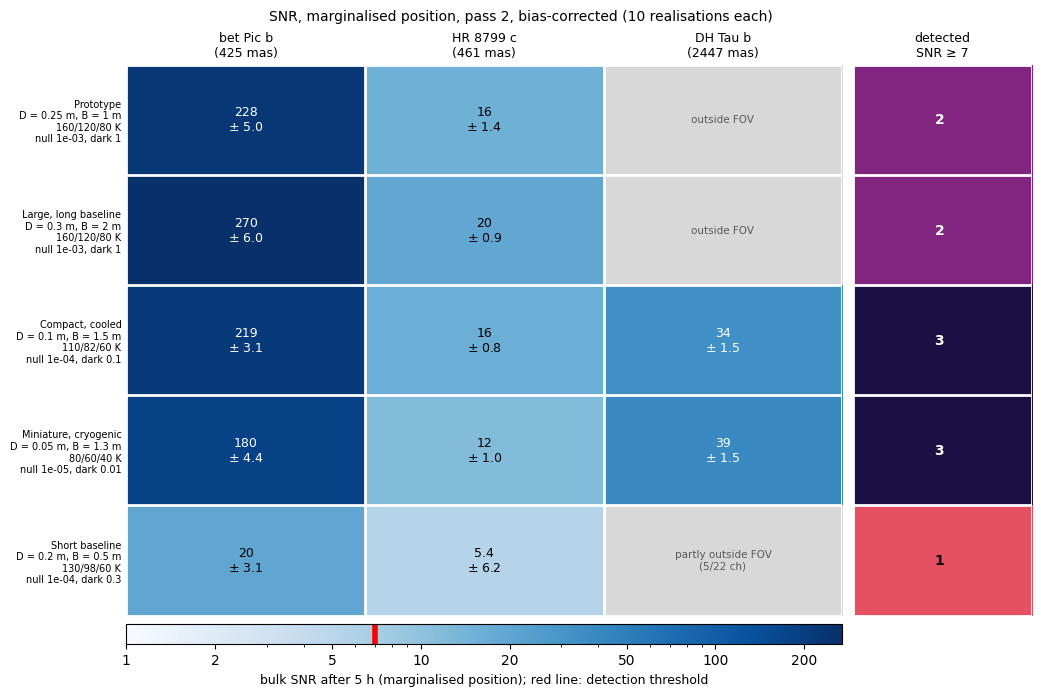

In [54]:
# --- What to show (see the table above) ---
CASE = 'marg'               # 'marg' (marginalised position) or 'known' (known position)
ESTIMATE = 'SNR'            # 'SNR', 'SNR_uncorrected', 'proto_corrected', 'proto_reported' or 'SNR_fisher'
SNR_DETECTION = 7           # a planet counts as detected if the shown SNR after T_OBS reaches this

CASE_LABELS = {'marg': 'marginalised position', 'known': 'known position'}
ESTIMATE_LABELS = {'SNR': 'pass 2, bias-corrected', 'SNR_uncorrected': 'pass 2, not bias-corrected',
                   'proto_corrected': 'pass 1 (prototype), bias-corrected',
                   'proto_reported': 'pass 1 (prototype) as reported', 'SNR_fisher': 'Fisher expectation'}

plt.rcParams.update({'savefig.dpi': 300})
names = list(SETUPS)
planets = list(TARGETS)
SETUP_LABELS = {n: f"{n}\nD = {p['D']:g} m, B = {p['B']:g} m\n"
                   f"{p['T_mirror']:g}/{p['T_instr']:g}/{p['T_det']:g} K\n"
                   f"null {p['null_depth']:.0e}, dark {p['dark_current']:g}"
                for n, p in SETUPS.items()}

rows = summary[summary.case == CASE]
snr_table = rows.pivot(index='setup', columns='target', values=ESTIMATE).loc[names, planets]
# per-observation scatter, only computed for the result (pass 2, bias-corrected)
err_table = rows.pivot(index='setup', columns='target', values='SNR_scatter').loc[names, planets] \
    if ESTIMATE == 'SNR' else snr_table * np.nan
status_table = rows.pivot(index='setup', columns='target', values='status').loc[names, planets]
sep_mas = {t: PREP[t, names[0]]['sep_mas'] for t in planets}

values = snr_table.where(status_table == 'ok').astype(float).values
detected = np.nan_to_num(values, nan=0) >= SNR_DETECTION      # outside the FOV counts as not detected
n_detected = detected.sum(axis=1)

fig = plt.figure(figsize=(2.1 * len(planets) + 4, 0.85 * len(names) + 2.6), layout='constrained')
grid = fig.add_gridspec(2, 2, width_ratios=[len(planets), 0.75], height_ratios=[len(names), 0.18])
ax, ax_count, cax = fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[0, 1]), fig.add_subplot(grid[1, 0])

# --- SNR per planet and setup ---
finite = values[np.isfinite(values) & (values > 0)]
# log scale from SNR 1; lower values (e.g. 0 after the noise-bias correction) get the lowest colour
norm = LogNorm(vmin=1, vmax=max(finite.max(), 10) if finite.size else 10, clip=True)
cmap = plt.get_cmap('Blues').copy()
cmap.set_bad('0.85')                                   # cells without a value: planet (partly) outside the FOV
image = ax.imshow(np.ma.masked_invalid(values), cmap=cmap, norm=norm, aspect='auto')
for (row, col), value in np.ndenumerate(values):
    if np.isfinite(value):
        err = err_table.values[row, col]
        text = f'{value:.0f}' if value >= 10 else f'{value:.1f}'
        if np.isfinite(err):
            #text += f'\n± {err:.1f}'
            text += f'\n'  + rf'$\pm$ {err:.1f}'
        ax.text(col, row, text, ha='center', va='center', fontsize=9,
                color='white' if norm(value) > 0.6 else 'black')
    else:
        ax.text(col, row, status_table.values[row, col].replace(' (', '\n('), ha='center', va='center',
                fontsize=7.5, color='0.35')
ax.set_xticks(range(len(planets)), [f'{t}\n({sep_mas[t]:.0f} mas)' for t in planets], fontsize=9)
ax.set_yticks(range(len(names)), [SETUP_LABELS[n] for n in names], fontsize=7)
ax.xaxis.tick_top()

# --- Detections per setup ---
# one shade of green per possible count, light (0) to dark (all planets); a different hue from the SNR scale
count_colors = plt.get_cmap('Greens')(np.linspace(0.12, 0.85, len(planets) + 1))
ax_count.imshow(n_detected[:, None], cmap='magma_r', vmin=-0.5, vmax=len(planets) + 0.5, # ListedColormap(count_colors)
                aspect='auto')
for row, n in enumerate(n_detected):
    ax_count.text(0, row, f'{n} ', ha='center', va='center', fontsize=10, fontweight='bold',
                  color='white' if n / len(planets) > 0.5 else 'black')
ax_count.set_xticks([0], [f'detected\nSNR ≥ {SNR_DETECTION:g}'], fontsize=9)
ax_count.xaxis.tick_top()
ax_count.set_yticks([])

for a, n_cols in ((ax, len(planets)), (ax_count, 1)):
    a.tick_params(length=0)
    for spine in a.spines.values():
        spine.set_visible(False)
    a.set_xticks(np.arange(n_cols + 1) - 0.5, minor=True)
    a.set_yticks(np.arange(len(names) + 1) - 0.5, minor=True)
    a.grid(which='minor', color='white', lw=2)
    a.tick_params(which='minor', length=0)

# --- Colour bar below, with the detection threshold ---
colorbar = fig.colorbar(image, cax=cax, orientation='horizontal')
ticks = [t for t in (1, 2, 5, 10, 20, 50, 100, 200, 500, 1000) if t <= norm.vmax]
colorbar.set_ticks(ticks, labels=[f'{t:g}' for t in ticks])
colorbar.set_label(f'bulk SNR after {T_OBS / 3600:g} h ({CASE_LABELS[CASE]}); red line: detection threshold',
                   fontsize=9)
cax.axvline(SNR_DETECTION, color='red', lw=4)

fig.suptitle(f'SNR, {CASE_LABELS[CASE]}, {ESTIMATE_LABELS[ESTIMATE]} ({N_REALISATIONS} realisations each)',
             fontsize=10)
fig.savefig(COMBINED_DIR / f'snr_heatmap_{CASE}_{ESTIMATE}.png', transparent=True)
plt.show()